In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem
from math import factorial
import pickle

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
b0 = 1
b1 = 5e-1
b2 = 1e-1
sigma0 = 5e-1
sigma2 = 1e-1

params = {'b0': b0, 'b1': b1, 'b2': b2,
          'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
          'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
          'T': 0.5, 'Nt': 1_000}

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

In [3]:
max_order_x = 8
max_order_fn = 9
poly_deg = 10
max_order_F = 4

In [4]:
F_HJB = lqproblem.strategy_hjb_sig_functional(env, poly_deg, max_order_F)

In [5]:
np.random.seed(456)
dim = 2
order = max_order_F

# with open('W_sig_1.pkl', 'rb') as f:
#     W_sig_expected = pickle.load(f)
#     f.close()

max_order = max(max_order_x, max_order_fn, max_order_F)

W_sig_expected = lqproblem.fawcett(env, max_order)
#W_sig = W_sig_expected.flatten()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()
    
#env = lqproblem.environment(**params)
optimiser_1 = optimiser_lqproblem.Optimiser(env, W_sig_expected, order = order, max_order_fn = max_order_fn)
#F = ta.sig_to_tensor(F, env.dim, order)
#optimiser_1.F = F

In [6]:
# with open('W_sig_1.pkl', 'rb') as f:
#     W_sig_expected_empirical = pickle.load(f)
#     f.close()

In [7]:
# W_sig_expected

In [8]:
# W_sig_expected_empirical.truncate(max_order_x)

In [9]:
np.random.seed(456)
n_epochs = 20
lr = 1

optimiser_1.train_sgd(n_epochs, lr = lr, max_order_x = max_order_x, max_order_fn = max_order_fn, truncate_fn = True, method='SGD')

F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

[109.25634452]: 100%|██████████| 20/20 [11:00<00:00, 33.05s/it]


In [10]:
F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [11]:
F

Tensor([-5.003513787657271, [0.18797211956448145, -0.11640802093527924], [[0.5588368788886566, -1.1974133330396703], [-1.1226269225291943, -1.0176745026155767]], [[[1.1671195821046316, -0.5607033476876613], [-1.086126752085247, -0.43676244667873976]], [[0.2723985431071121, -0.15704949014923159], [1.1342497879173672, -0.7943741921882034]]], [[[[-1.2825485609158043, -1.25249316787215], [-1.2631461713315575, 0.5882749929110043]], [[-0.16590749812733357, -0.47076650434175726], [1.7081731044680586, -1.1408832464601246]]], [[[-0.2960964618611261, 0.6095898158311369], [-1.3866855541975787, -0.5888811873081901]], [[-0.8364847789463432, -0.647969668522613], [-0.7968303035458163, 0.9704387286492013]]]]])

In [12]:
F_HJB

Tensor([-5.187486467101398, [0.6556570214873163, -0.7394958780569365], [[-0.08305410562017287, 0.009675753540030484], [0.08873950536640743, -0.07394958780569366]], [[[0.9638701539591824, -0.01703296670831009], [-0.001161090376643966, 0.0009675753540030487]], [[-0.010648740595763763, 0.008873950536640743], [0.00887395053664074, -0.007394958780569367]]], [[[[-41.0724956058241, -0.001409461487409058], [0.0020439527103858087, -0.001703296670831009]], [[0.00013932754544656234, -0.00011610903766439665], [-0.00011610903766439719, 9.675753540030487e-05]]], [[[0.0012778455665870495, -0.0010648740595763763], [-0.001064874059576377, 0.0008873950536640743]], [[-0.001064874059576377, 0.0008873950536640743], [0.0008873950536640741, -0.0007394958780569368]]]]])

In [13]:
F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [14]:
# # F = optimiser_1.F

# # strag_sig = lqproblem.sig_strag_dot(F, order = order)

# with open('F_optimised_problem2.pkl', 'wb') as f:
#     pickle.dump(F.flatten(), f)
#     f.close()

In [15]:
np.random.seed(123)

nsims = 100

env.simulate(nsims, strag_sig, max_order_x)

C:\Users\User\Documents\GitHub\optimal-control-with-signatures\notebooks\../src\lqproblem.py:136: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  strag[nsim] = F.dot(W_sig)


In [16]:
np.random.seed(123)

#nsims = 100

env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, max_order_x)

In [17]:
np.random.seed(123)

strag_hjb_sig = lqproblem.sig_strag_dot(F_HJB, order = order)

env_hjb_sig.simulate(nsims, strag_hjb_sig, max_order_x)

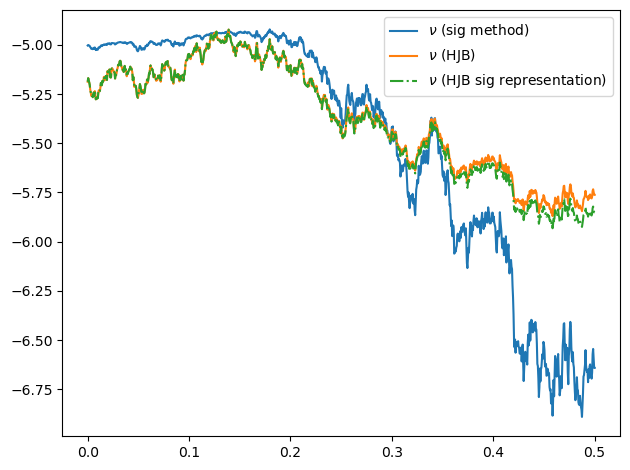

In [18]:
nsim = 0

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$ (sig method)')
plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)')
plt.plot(env.timesteps, env_hjb_sig.nu[:,nsim], label=r'$\nu$ (HJB sig representation)', linestyle='-.')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

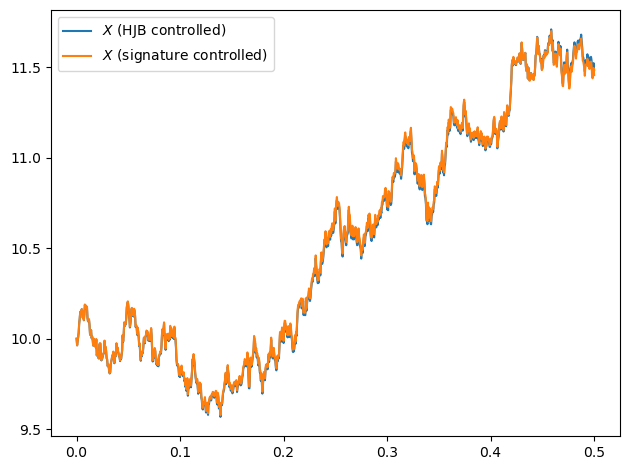

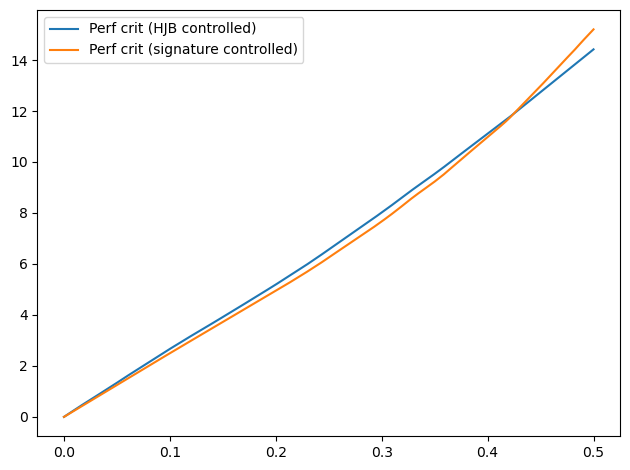

In [19]:
plt.plot(env.timesteps, env_hjb.X[:,nsim], label=r'$X$ (HJB controlled)')
plt.plot(env.timesteps, env.X[:, nsim], label=r'$X$ (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env_hjb.run_crit[:,nsim], label=r'Perf crit (HJB controlled)')
plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
print(f'Performance criterion\nSig: {env.performance.mean()}')

Performance criterion
Sig: 110.51906977729315


In [21]:
print(f'Performance criterion\nHJB: {env_hjb.performance.mean()}')

Performance criterion
HJB: 110.4897699350773


In [22]:
optimiser_1.value_fn(F, max_order_x = max_order_x, truncate_fn = True, max_order_fn = max_order_fn)

tensor([109.2504], grad_fn=<AddBackward0>)

In [23]:
# # f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# # f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# # f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

# max_order = max(max_order_x, max_order_fn)

# nsim = 1

# LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_x)
# p_perf = optimiser_1.p_perf
# p_perf_run = optimiser_1.p_perf_run

# f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
# f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

# X_sig = np.zeros((env.Nt+1,))
# perf_hist = np.zeros((env.Nt+1,))

# W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

# X_sig[0] = f_x_sig(env,W_sig,dim,0)
# perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# # S_sig = f_s_sig(env)
# # alpha_hat_sig = f_alpha_sig(env)
# # perf_hist = f_perf_crit(env)

# for it in range(1,env.Nt+1):
#     path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
#     W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
#     X_sig[it] = f_x_sig(env,W_sig,dim,it)
#     perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
#     #S_sig[it,:] = strag_sig(env,it)

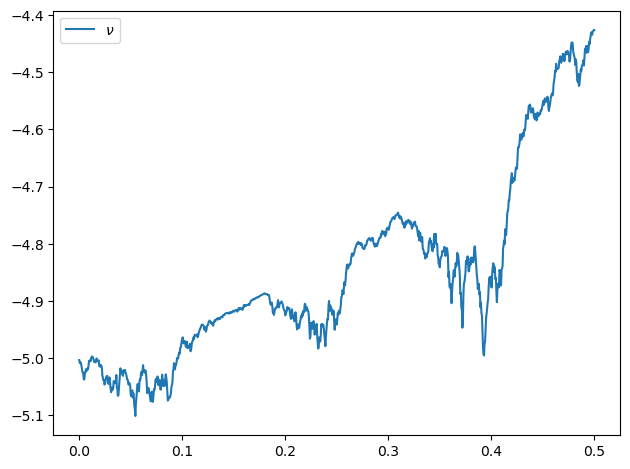

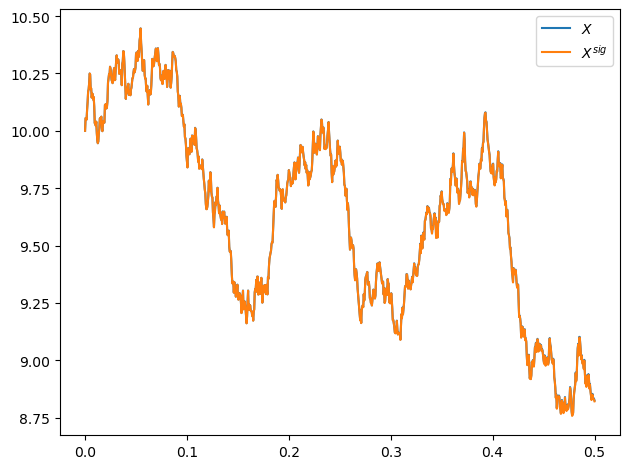

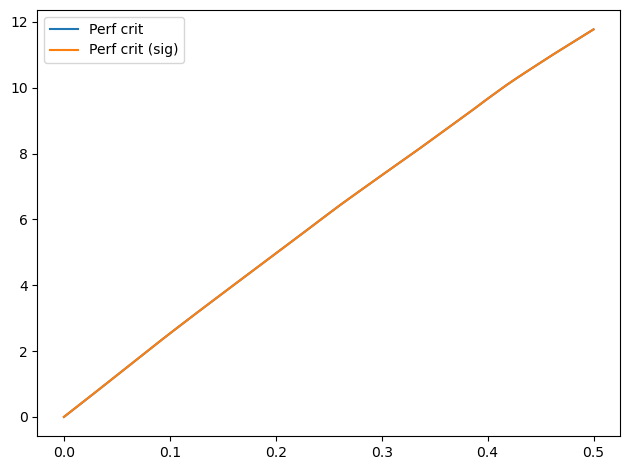

In [24]:
nsim = 5

max_order = max(max_order_x, max_order_fn)

LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_fn//2)
p_perf, p_perf_run= optimiser_1.p_perf(optimiser_1.F, max_order = max_order_fn, return_running = True)

f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

X_sig = np.zeros((env.Nt+1,))
perf_hist = np.zeros((env.Nt+1,))

W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

X_sig[0] = f_x_sig(env,W_sig,dim,0)
perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(1,env.Nt+1):
    path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
    W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
    X_sig[it] = f_x_sig(env,W_sig,dim,it)
    perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
    #S_sig[it,:] = strag_sig(env,it)

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.X[:,nsim], label=r'$X$')
plt.plot(env.timesteps, X_sig[:], label=r'$X^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()

In [26]:
LF.order

4